---
title: "Czy falochron ochroni plażę?"
author: "Ignacy Hejmej"
date: "11-21-2026"
lang: pl
date-format: "D MMMM YYYY"
bibliography: refs.bib
nocite: '@*'
format:
  pdf:
    documentclass: article
    geometry:
      - top=10mm
      - bottom=15mm
      - left=18mm
      - right=18mm
    fig-pos: "H"
execute:
  echo: false
  warning: false
---

In [ ]:
%config InlineBackend.figure_format = 'svg'
import os
os.environ['NUMBA_THREADING_LAYER'] = 'workqueue'
from IPython.display import Markdown
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot
from open_atmos_jupyter_utils import show_plot, show_anim
from PyMPDATA import ScalarField, Solver, Stepper, VectorField, Options, boundary_conditions
mpl.rcParams.update({
        "text.usetex": True,
        "font.family": "serif",
        "font.size": 10,
        "axes.labelsize": 8.5,
        "axes.titlesize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 7.5,
        "figure.figsize": (6.85,2.6),
        "text.latex.preamble": r"""
            \usepackage[T1]{fontenc}
            \usepackage[utf8]{inputenc}
            \usepackage[polish]{babel}
            \usepackage{amsmath}
            \usepackage{lmodern}
        """,
    })


In [2]:
class ShallowWaterEquationsIntegratorWithBathymetry:
    def __init__(self, *, h_initial: np.ndarray, bathymetry: np.ndarray, uh_initial: np.ndarray = None, options: Options = None):
        options = options or Options(nonoscillatory=True, infinite_gauge=True)
        self.bathymetry = bathymetry
        X, Y, grid = 0, 1, h_initial.shape
        stepper = Stepper(options=options, grid=grid)
        kwargs = {
            'boundary_conditions': [boundary_conditions.Periodic()] * len(grid),
            'halo': options.n_halo,
        }
        advectees = {
            "h": ScalarField(h_initial, **kwargs),
            "uh": ScalarField(np.zeros(grid) if uh_initial is None else uh_initial, **kwargs),
            "vh": ScalarField(np.zeros(grid), **kwargs),
        }
        self.advector = VectorField((
                np.zeros((grid[X] + 1, grid[Y])),
                np.zeros((grid[X], grid[Y] + 1))
            ), **kwargs
        )
        self.solvers = { k: Solver(stepper, v, self.advector) for k, v in advectees.items() }

    def __getitem__(self, key):
        return self.solvers[key].advectee.get()
    
    def _apply_half_rhs(self, *, key, axis, g_times_dt_over_dxy):
        self[key][:] -= g_times_dt_over_dxy/2 * self['h'] * np.gradient(self['h'] - self.bathymetry,axis=axis)

    def _update_courant_numbers(self, *, axis, key, mask, dt_over_dxy):
        velocity = np.where(mask, np.nan, 0)
        momentum = self[key]
        np.divide(momentum, self['h'], where=mask, out=velocity)

        all = slice(None, None) 
        all_but_last = slice(None, -1)
        all_but_first_and_last = slice(1, -1)

        velocity_at_cell_boundaries = velocity[( 
            (all_but_last, all),
            (all, all_but_last),
        )[axis]] + np.diff(velocity, axis=axis) / 2 
        courant_number = self.advector.get_component(axis)[(
            (all_but_first_and_last, all),
            (all, all_but_first_and_last)
        )[axis]]
        courant_number[:] = velocity_at_cell_boundaries * dt_over_dxy[axis]
        assert np.amax(np.abs(courant_number)) <= 1

    def __call__(self, *, nt: int, g: float, dt_over_dxy: tuple, outfreq: int, eps: float=1e-7):
        output = {k: [] for k in self.solvers.keys()}
        for it in range(nt + 1): 
            if it != 0:
                mask = self['h'] > eps
                for axis, key in enumerate(("uh", "vh")):
                    self._update_courant_numbers(axis=axis, key=key, mask=mask, dt_over_dxy=dt_over_dxy)
                self.solvers["h"].advance(n_steps=1)
                for axis, key in enumerate(("uh", "vh")):
                    self._apply_half_rhs(key=key, axis=axis, g_times_dt_over_dxy=g * dt_over_dxy[axis])
                    self.solvers[key].advance(n_steps=1)
                    self._apply_half_rhs(key=key, axis=axis, g_times_dt_over_dxy=g * dt_over_dxy[axis])
            if it % outfreq == 0:
                for key in self.solvers.keys():
                    output[key].append(self[key].copy())
        return output

In [3]:
grid_shape = (160, 40)
xi, yi = np.indices(grid_shape)
b0 = 1.0
obstacle_height = 0.7

bars_x = [10, 25, 40, 55, 70, 85, 100]
sigma_bar = 3.5
bathymetry_obstacle = np.full(grid_shape, b0)
for xc in bars_x:
    bathymetry_obstacle -= obstacle_height * np.exp(-((xi - xc)**2 / (2 * sigma_bar**2)))

bathymetry_flat = np.full(grid_shape, b0)

wave_amplitude = 0.07
x_0, sigma_wave = 15.0, 3.5
zeta_initial = wave_amplitude * np.exp(-((xi - x_0)**2 / (2 * sigma_wave**2)))

h_initial_flat = bathymetry_flat + zeta_initial
h_initial_obstacle = bathymetry_obstacle + zeta_initial

u_initial = np.sqrt(9.81 / b0) * zeta_initial
uh_initial_flat = u_initial * h_initial_flat
uh_initial_obstacle = u_initial * h_initial_obstacle

output_obstacle = ShallowWaterEquationsIntegratorWithBathymetry(
    h_initial=h_initial_obstacle, bathymetry=bathymetry_obstacle, uh_initial=uh_initial_obstacle
)(
    g=9.81, nt=820, dt_over_dxy=(0.06, 0.06), outfreq=4
)

output_flat = ShallowWaterEquationsIntegratorWithBathymetry(
    h_initial=h_initial_flat, bathymetry=bathymetry_flat, uh_initial=uh_initial_flat
)(
    g=9.81, nt=820, dt_over_dxy=(0.06, 0.06), outfreq=4
)


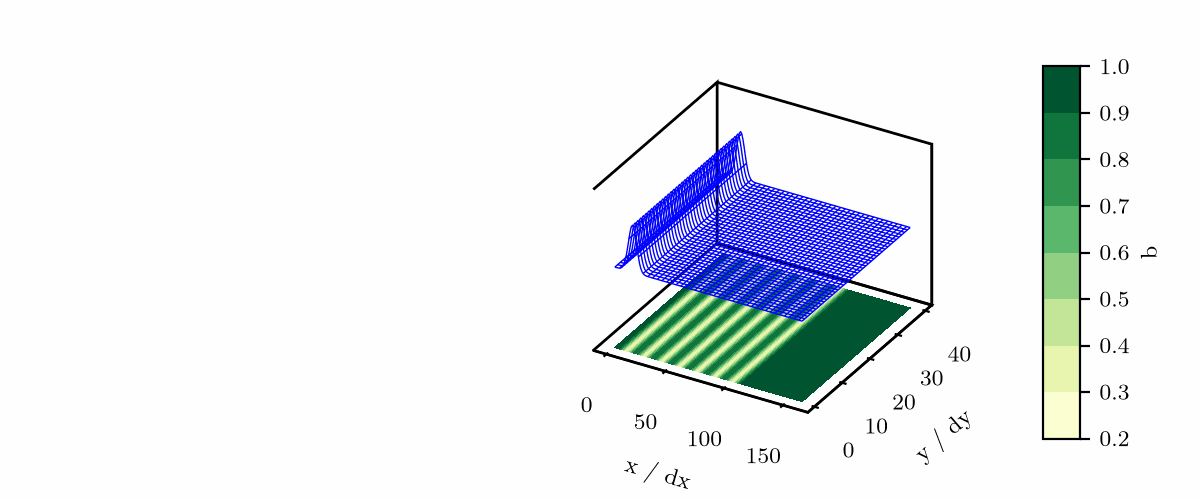

HTML(value="<a href='.\\flow1.gif' target='_blank'>.\\flow1.gif</a><br>")

In [ ]:
#| include: false
def plot_wave(i, *, zlim=(-0.12, 0.12)):
    fig, ax = pyplot.subplots(figsize=(7, 3.8), subplot_kw={"projection": "3d"}, dpi=200)
    surface_elevation = output_obstacle['h'][i] - bathymetry_obstacle
    ax.plot_wireframe(
        xi + 0.5, yi + 0.5, surface_elevation,
        color='blue', linewidth=0.5
    )
    ax.set_zlim(zlim)
    ax.set_box_aspect((3.5, 1.2, 0.6))
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.fill = False
        axis.pane.set_edgecolor('black')
        axis.pane.set_alpha(1.0)
    ax.grid(False)
    ax.set_zticks([])
    ax.set_xlabel("x / dx")
    ax.set_ylabel("y / dy")
    ax.set_proj_type('ortho')
    cnt = ax.contourf(
        xi + 0.5, yi + 0.5, bathymetry_obstacle, 
        zdir='z', offset=zlim[0], cmap='YlGn'
    )
    pyplot.colorbar(cnt, pad=0.1, aspect=10, fraction=0.04, label='b')
    return fig

show_anim(plot_wave, range(len(output_obstacle['h'])), gif_file="flow1.gif")

In [5]:
gauge_x, gauge_y = 130, 20

times_flat = [it * 4 * 0.06 for it in range(len(output_flat['h']))]
times_obs = [it * 4 * 0.06 for it in range(len(output_obstacle['h']))]

zeta_gauge_flat = [output_flat['h'][it][gauge_x, gauge_y] - bathymetry_flat[gauge_x, gauge_y] for it in range(len(output_flat['h']))]
zeta_gauge_obs = [output_obstacle['h'][it][gauge_x, gauge_y] - bathymetry_obstacle[gauge_x, gauge_y] for it in range(len(output_obstacle['h']))]

max_flat = max(zeta_gauge_flat)
max_obs = max(zeta_gauge_obs)

kt = max_obs / max_flat
md_kt = Markdown(f"{kt:.3f}")
kw = (1-kt**2)*100
md_kw = Markdown(f"{kw:.1f}")

mass_init = np.sum(output_obstacle['h'][0])
mass_final = np.sum(output_obstacle['h'][-1])

k1t = (1-kt)*100
md_k1t = Markdown(f"{k1t:.1f}")

assert abs(mass_final - mass_init) / mass_init < 1e-5
assert kt < 1.0

# Wstęp

W niniejszym dokumencie rozważono wpływ kształtu barymetrii zbiornika wodnego na napływającą falę. Badanym kształtem dna jest periodyczny falochron, którego celem jest zmniejszenie amplitudy padającego zaburzenia. Zjawisko wymodelowano wykorzystując równania płytkiej wody (S.W.E) i algorytm MPDATA. Obliczenia zaimplementowano w $\texttt{Pythonie}$ przy użyciu pakietu $\texttt{PyMPDATA}$. Do precyzyjnego zdefiniowania problemu postawiono pytanie badawcze:  

*W jakim stopniu periodyczny falochron podwodny wpływa na transmisję fali?*.

Do uzyskania odpowiedzi posłużą dwie metryki:

* współczynnik transmisji

$$
K_T = \frac{A_{\mathrm{max}}^{\mathrm{obs}}}{A_{\mathrm{max}}^{\mathrm{free}}},
$$ {#eq-wsp-trans}

* współczynnik osłabienia

$$
K_W = 1 - K_T^2,
$$ {#eq-wsp-oslb}

gdzie $A_{\mathrm{max}}^{\mathrm{obs}}$ i $A_{\mathrm{max}}^{\mathrm{free}}$ oznaczają odpowiednio maksymalną amplitudę fali mierzoną przy końcowym położeniu dla przypadku z przeszkodą (falochronem) i bez.

# Rezultaty

Symulacje wykonano na siatce 160x40 m i trwały 49.2 s ($dx = 1$ m, $dt = 0.06$ s, liczba kroków czasowych = 820). Warunkiem począktowym było eksponencjalne zaburzenie z prędkością w osi $x$. Rozważono dwa przypadki: dno płaskie oraz dno z falochronem zrealizowanym za pomocą periodycznych eksponent. Dynamikę progagacji dla przypadku z falochronem zwizualizowano w załączonej do artefaktów animacji *flow1.gif*.

Na rysunku -@fig-czujnik a) przedstawiono przekrój zjawiska wzdłuż osi $x$ dla $y = 20$ w 720 kroku czasowym. Dla przypadku z przeszkodą można zaobserwować jej bezpośredni pływ na kształt płynu. Rysunek -@fig-czujnik b) przedstawia zależność $\zeta$, która odpowiada ampludzie fali, od czasu w położeniu czujnika. Ustawienie czujnika w punkcie (130, 20) pozwala na pomiar amplitudy chwilę po przejściu przez falochron kiedy przepływ jest ustabilizowany, można to miejsce interpretować jako brzeg plaży. Zaobserwowano zmniejszenie amplitudy oraz opóźnienie fali, co świadczy o prawidłowym działaniu falochronu. Na podstawie wyników obliczono wartości współczynnika transmisji oraz osłabienia:

$$
K_T = `{python} md_kt`, K_W = `{python} md_kw` \%.
$$

Odpowiedź na zadane wcześniej pytanie badawcze jest zatem następująca:

*Periodyczny falochron podwodny zmniejsza amplitudę fali o `{python} md_k1t`\% i powoduje, że staje się słabsza o `{python} md_kw`\%*

Czyli w badanym zjawisku falochron zmniejszy szkody wywołane na brzegu o połowę oraz opóźni ich wystąpienie. 

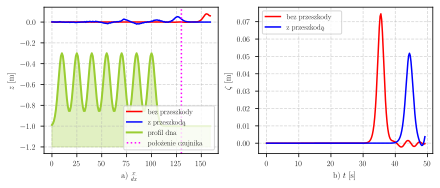

In [ ]:
#| label: fig-czujnik
#| fig-cap: 'Przebiegi fal dla przypadku swobodnego i tłumionego. Wykres a) przedstawia przekrój poprzeczny zjawiska dla 720 kroku czasowego. Na wykresie b) narysowano zależność $\zeta$ od czasu w położeniu czujnika (130, 20)'
#| fig-pos: "H"
#| out-width: "100%"

pyplot.figure(layout='constrained')
pyplot.subplot(1,2,2)
pyplot.plot(times_flat, zeta_gauge_flat, label='bez przeszkody', color='red')
pyplot.plot(times_obs, zeta_gauge_obs, label='z przeszkodą', color='blue')
pyplot.xlabel('b) $t$ [s]')
pyplot.ylabel(r'$\zeta$ [m]')
pyplot.grid(True, linestyle='--', alpha=0.5)
pyplot.legend()

it_snap = 180
x_axis = np.arange(grid_shape[0])
surface_flat_snap = output_flat['h'][it_snap][:, gauge_y] - bathymetry_flat[:, gauge_y]
surface_obs_snap = output_obstacle['h'][it_snap][:, gauge_y] - bathymetry_obstacle[:, gauge_y]
bed_profile = -bathymetry_obstacle[:, gauge_y]

pyplot.subplot(1,2,1)
pyplot.plot(x_axis, surface_flat_snap, label='bez przeszkody', color='red')
pyplot.plot(x_axis, surface_obs_snap, label='z przeszkodą', color='blue')
pyplot.plot(x_axis, bed_profile, label='profil dna', color='yellowgreen', linewidth=2)
pyplot.fill_between(x_axis, bed_profile, -1.2, color='yellowgreen', alpha=0.3)
pyplot.axvline(gauge_x, color='magenta', linestyle=':', label='położenie czujnika')
pyplot.xlabel(r'a) $\frac{x}{dx}$')
pyplot.ylabel('$z$ [m]')
pyplot.grid(True, linestyle='--', alpha=0.5)
pyplot.legend(loc='lower right')

# Zbieżność algorytmu

Na rysunku -@fig-zbieznosc przedstawiono zbieżność algorytmu, badaną dla przypadku z falochronem.

In [7]:
dt_ratios = [0.08, 0.06, 0.04, 0.02, 0.01]
t_target = 46.4
max_values = {}
for r in dt_ratios:
    nt_steps = int(round(t_target / r))
    out_obs = ShallowWaterEquationsIntegratorWithBathymetry(
        h_initial=h_initial_obstacle, bathymetry=bathymetry_obstacle, uh_initial=uh_initial_obstacle
    )(
        g=9.81, nt=nt_steps, dt_over_dxy=(r, r), outfreq=1
    )
    
    z_obs = [out_obs['h'][it][gauge_x, gauge_y] - bathymetry_obstacle[gauge_x, gauge_y] for it in range(len(out_obs['h']))]
    max_values[r] = max(z_obs)
ref_val = max_values[0.01]
test_ratios = [0.08, 0.06, 0.04, 0.02]
errors_pct = [abs(max_values[r] - ref_val) / ref_val * 100 for r in test_ratios]

assert errors_pct[2] <= errors_pct[1] <= errors_pct[0]
assert errors_pct[2] < 3.0

In [8]:
nx_targets = [80, 120, 140, 160]
max_spatial = {}
cfl_ratio = 0.04
t_sim = 46.4

for nx in nx_targets:
    dx = 160.0 / nx
    grid = (nx, 20)
    xi, yi = np.indices(grid)
    x_coords = xi * dx
    
    b0 = 1.0
    obstacle_height = 0.7
    bars_x = [10.0, 25.0, 40.0, 55.0, 70.0, 85.0, 100.0]
    sigma_bar = 3.5
    bath_obs = np.full(grid, b0)
    for xc in bars_x:
        bath_obs -= obstacle_height * np.exp(-((x_coords - xc)**2 / (2 * sigma_bar**2)))
        
    wave_amplitude = 0.07
    x_0, sigma_wave = 15.0, 3.5
    zeta_init = wave_amplitude * np.exp(-((x_coords - x_0)**2 / (2 * sigma_wave**2)))
    
    h_init = bath_obs + zeta_init
    u_init = np.sqrt(9.81 / b0) * zeta_init
    uh_init = u_init * h_init
    
    dt = cfl_ratio * dx
    nt_steps = int(round(t_sim / dt))
    
    out_spatial = ShallowWaterEquationsIntegratorWithBathymetry(
        h_initial=h_init, bathymetry=bath_obs, uh_initial=uh_init
    )(
        g=9.81, nt=nt_steps, dt_over_dxy=(cfl_ratio, cfl_ratio), outfreq=1
    )
    
    gx_idx = int(round(130.0 / dx))
    gy_idx = 10
    
    zeta_series = [out_spatial['h'][it][gx_idx, gy_idx] - bath_obs[gx_idx, gy_idx] for it in range(len(out_spatial['h']))]
    max_spatial[nx] = max(zeta_series)

ref_spatial = max_spatial[160]
spatial_test_nx = [80, 120, 140]
spatial_errors = [abs(max_spatial[n] - ref_spatial) / ref_spatial * 100 for n in spatial_test_nx]
spatial_dx = [160.0 / n for n in spatial_test_nx]

assert spatial_errors[2] <= spatial_errors[1] <= spatial_errors[0]

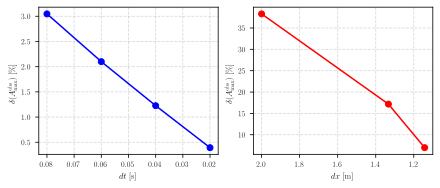

In [ ]:
#| label: fig-zbieznosc
#| fig-cap: 'Błąd względny $A_{\mathrm{max}}^{\mathrm{obs}}$ w zależności od kroku czasowego i przestrzennego. '
#| fig-pos: "H"
#| out-width: "100%"

pyplot.figure(layout='constrained')
pyplot.subplot(1,2,1)
pyplot.plot(test_ratios, errors_pct, 'o-', color='blue')
pyplot.xlabel(r'$dt$ [s]')
pyplot.ylabel(r'$\delta (A_{\mathrm{max}}^{\mathrm{obs}})$ [\%]')
pyplot.grid(True, linestyle='--', alpha=0.5)
pyplot.gca().invert_xaxis()

pyplot.subplot(1,2,2)
pyplot.plot(spatial_dx, spatial_errors, 'o-', color='red')
pyplot.xlabel(r'$dx$ [m]')
pyplot.ylabel(r'$\delta (A_{\mathrm{max}}^{\mathrm{obs}})$ [\%]')
pyplot.grid(True, linestyle='--', alpha=0.5)
pyplot.gca().invert_xaxis()

Zbieżność czasową badano dla stałego kroku przestrzennego $dx = 1$ m względem symulacji z referencyjną wartością $dt = 0.01$. Przy badaniu zbieżności przestrzennej założono wartość referencyjną $dx = 1$ m, a $dt$ było dobierane automatycznie, tak aby zachować stały stosunek $\frac{dt}{dx} = 0.04$. Ciągła monotoniczność wykresów świadczy o prawidłowym zachowaniu algorymtu. 

# Bibliografia
::: {#refs} :::